
## ENIAC Project 02
## by maJEStic PyLots ✈

# 01 Data Exploration

In [ ]:
import pandas as pd

In [ ]:
# orders.csv
orders_df = pd.read_csv(
    "https://raw.githubusercontent.com/JuliaAltmann/ENIAC-Sales-Discount-Analysis/main/data/raw/orders.csv"
)
ord_df = orders_df.copy()


# orderlines.csv
orderlines_df = pd.read_csv(
    "https://raw.githubusercontent.com/JuliaAltmann/ENIAC-Sales-Discount-Analysis/main/data/raw/orderlines.csv"
)
oli_df = orderlines_df.copy()

1.1 Orders & Orderlines

In [ ]:
ord_df.head()

,order_id,created_date,total_paid,state
0,241319,2017-01-02 13:35:40,44.99,Cancelled
1,241423,2017-11-06 13:10:02,136.15,Completed
2,242832,2017-12-31 17:40:03,15.76,Completed
3,243330,2017-02-16 10:59:38,84.98,Completed
4,243784,2017-11-24 13:35:19,157.86,Cancelled


In [ ]:
ord_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226909 entries, 0 to 226908
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   order_id      226909 non-null  int64  
 1   created_date  226909 non-null  object 
 2   total_paid    226904 non-null  float64
 3   state         226909 non-null  object 
dtypes: float64(1), int64(1), object(2)
memory usage: 6.9+ MB


In [ ]:
oli_df.head()

,id,id_order,product_id,product_quantity,sku,unit_price,date
0,1119109,299539,0,1,OTT0133,18.99,2017-01-01 00:07:19
1,1119110,299540,0,1,LGE0043,399.00,2017-01-01 00:19:45
2,1119111,299541,0,1,PAR0071,474.05,2017-01-01 00:20:57
3,1119112,299542,0,1,WDT0315,68.39,2017-01-01 00:51:40
4,1119113,299543,0,1,JBL0104,23.74,2017-01-01 01:06:38


In [ ]:
oli_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 293983 entries, 0 to 293982
Data columns (total 7 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   id                293983 non-null  int64 
 1   id_order          293983 non-null  int64 
 2   product_id        293983 non-null  int64 
 3   product_quantity  293983 non-null  int64 
 4   sku               293983 non-null  object
 5   unit_price        293983 non-null  object
 6   date              293983 non-null  object
dtypes: int64(4), object(3)
memory usage: 15.7+ MB


In [ ]:
ord_df.isna().sum()

,0
order_id,0
created_date,0
total_paid,5
state,0


In [ ]:
ord_df.shape
print('Zeilen insgesamt: ', ord_df.shape[0])
print('Spalten insgesamt: ', ord_df.shape[1])

Zeilen insgesamt:  226909
Spalten insgesamt:  4


In [ ]:
ord_df.describe()

,order_id,total_paid
count,226909.000000,226904.000000
mean,413296.482480,569.225818
std,65919.250331,1761.778002
min,241319.000000,0.000000
25%,356263.000000,34.190000
50%,413040.000000,112.990000
75%,470553.000000,525.980000
max,527401.000000,214747.530000


In [ ]:
oli_df.describe()

,id,id_order,product_id,product_quantity
count,2.939830e+05,293983.000000,293983.0,293983.000000
mean,1.397918e+06,419999.116544,0.0,1.121126
std,1.530096e+05,66344.486479,0.0,3.396569
min,1.119109e+06,241319.000000,0.0,1.000000
25%,1.262542e+06,362258.500000,0.0,1.000000
50%,1.406940e+06,425956.000000,0.0,1.000000
75%,1.531322e+06,478657.000000,0.0,1.000000
max,1.650203e+06,527401.000000,0.0,999.000000


In [ ]:
oli_df.shape
print('Zeilen insgesamt: ', oli_df.shape[0])
print('Spalten insgesamt: ', oli_df.shape[1])

Zeilen insgesamt:  293983
Spalten insgesamt:  7


In [ ]:
oli_df.isna().sum()

,0
id,0
id_order,0
product_id,0
product_quantity,0
sku,0
unit_price,0
date,0


In [ ]:
ord_df.size

907636

In [ ]:
oli_df.size

2057881

1.2 products

# 02 Data Cleaning

02.1 Orders ("ord_df")

In [ ]:
ord_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226909 entries, 0 to 226908
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   order_id      226909 non-null  int64  
 1   created_date  226909 non-null  object 
 2   total_paid    226904 non-null  float64
 3   state         226909 non-null  object 
dtypes: float64(1), int64(1), object(2)
memory usage: 6.9+ MB


In [ ]:
ord_df.columns

Index(['order_id', 'created_date', 'total_paid', 'state'], dtype='object')

In [ ]:
ord_df.duplicated().sum()

np.int64(0)

In [ ]:
ord_df["created_date"] = pd.to_datetime(ord_df["created_date"], errors="coerce")

ord_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226909 entries, 0 to 226908
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   order_id      226909 non-null  int64         
 1   created_date  226909 non-null  datetime64[ns]
 2   total_paid    226904 non-null  float64       
 3   state         226909 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 6.9+ MB


In [ ]:
# count missing values in total_paid

num_missing = ord_df['total_paid'].isna().sum()
total_rows = ord_df.shape[0]
percent_missing = (100*num_missing/total_rows)
print(f"5 missing values represents {percent_missing:.5f}% of the rows in our DataFrame")

5 missing values represents 0.00220% of the rows in our DataFrame


In [ ]:
# A quick way to find out a percentage if you don't need to print out a sentence

ord_df['total_paid'].isna().value_counts(normalize=True)

,proportion
total_paid,
False,0.999978
True,0.000022


In [ ]:
ord_df.loc[ord_df['total_paid'].isna()]

,order_id,created_date,total_paid,state
127701,427314,2017-11-20 18:54:39,NaN,Pending
132013,431655,2017-11-22 12:15:24,NaN,Pending
147316,447411,2017-11-27 10:32:37,NaN,Pending
148833,448966,2017-11-27 18:54:15,NaN,Pending
149434,449596,2017-11-27 21:52:08,NaN,Pending


In [ ]:
# delete rows with Nan in total_paid
ord_df = ord_df.dropna(axis=0)

In [ ]:
# rename the columns
ord_df = ord_df.rename(columns={
    'order_id': 'id_order',
    'state': 'status'
})
ord_df.columns

Index(['id_order', 'created_date', 'total_paid', 'status'], dtype='object')

In [ ]:
ord_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 226904 entries, 0 to 226908
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id_order      226904 non-null  int64         
 1   created_date  226904 non-null  datetime64[ns]
 2   total_paid    226904 non-null  float64       
 3   status        226904 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 8.7+ MB


02.2 Orderlines (oli_df)

There are no missing values in orderlines_df

In [ ]:
oli_df.columns

Index(['id', 'id_order', 'product_id', 'product_quantity', 'sku', 'unit_price',
       'date'],
      dtype='object')

In [ ]:
oli_df.duplicated().sum()

np.int64(0)

In [ ]:
oli_df["date"] = pd.to_datetime(oli_df["date"], errors="coerce")

oli_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 293983 entries, 0 to 293982
Data columns (total 7 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   id                293983 non-null  int64         
 1   id_order          293983 non-null  int64         
 2   product_id        293983 non-null  int64         
 3   product_quantity  293983 non-null  int64         
 4   sku               293983 non-null  object        
 5   unit_price        293983 non-null  object        
 6   date              293983 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(4), object(2)
memory usage: 15.7+ MB


In [ ]:
oli_df.head(10)

,id,id_order,product_id,product_quantity,sku,unit_price,date
0,1119109,299539,0,1,OTT0133,18.99,2017-01-01 00:07:19
1,1119110,299540,0,1,LGE0043,399.00,2017-01-01 00:19:45
2,1119111,299541,0,1,PAR0071,474.05,2017-01-01 00:20:57
3,1119112,299542,0,1,WDT0315,68.39,2017-01-01 00:51:40
4,1119113,299543,0,1,JBL0104,23.74,2017-01-01 01:06:38
5,1119114,295310,0,10,WDT0249,231.79,2017-01-01 01:14:27
6,1119115,299544,0,1,APP1582,1.137.99,2017-01-01 01:17:21
7,1119116,299545,0,1,OWC0100,47.49,2017-01-01 01:46:16
8,1119119,299546,0,1,IOT0014,18.99,2017-01-01 01:50:34
9,1119120,295347,0,1,APP0700,72.19,2017-01-01 01:54:11


In [ ]:
# Count the number of decimal points in the unit_price
oli_df['unit_price'].str.count(r"\.").value_counts()

,count
unit_price,
1,257814
2,36169


In [ ]:
# Each row of orderlines represents a product in an order. For example, if order number 175 contained 3 seperate products, then order 175 would have 3 rows in orderlines, one row for each of the products. If 2 of those products have 'normal' prices (14.99, 15.85) and 1 has a price with 2 decimal points (1.137.99), we need to remove the whole order and not just the affected row. If we only remove the row with 2 decimal places then any later analysis about products and prices could be misleading.

# We therefore need to find the order numbers associated with the rows that have 2 decimal points, and then remove all the associated rows.


# 1) Boolean mask to find the orders that contain a price with multiple decimal points
lines_with_two_dots_mask = oli_df["unit_price"].str.count(r"\.")>1

oli_df.loc[lines_with_two_dots_mask]


,id,id_order,product_id,product_quantity,sku,unit_price,date
6,1119115,299544,0,1,APP1582,1.137.99,2017-01-01 01:17:21
11,1119126,299549,0,1,PAC0929,2.565.99,2017-01-01 02:07:42
15,1119131,299553,0,1,APP1854,3.278.99,2017-01-01 02:14:47
43,1119195,299582,0,1,PAC0961,2.616.99,2017-01-01 08:54:00
59,1119214,299596,0,1,PAC1599,2.873.99,2017-01-01 09:53:11
...,...,...,...,...,...,...,...
293862,1649999,452946,0,1,APP2075,2.999.00,2018-03-14 13:03:33
293887,1650045,527321,0,1,PAC2148,3.497.00,2018-03-14 13:10:15
293889,1650050,527324,0,1,PAC2117,3.075.00,2018-03-14 13:10:56
293911,1650088,527342,0,1,APP2492,1.329.00,2018-03-14 13:24:51


In [ ]:
# 2) Apply the boolean mask to the orderlines DataFrame. This way we can find the order_id of all the affected orders.
currupted_order_ids = oli_df.loc[lines_with_two_dots_mask, "id_order"]
currupted_order_ids

,id_order
6,299544
11,299549
15,299553
43,299582
59,299596
...,...
293862,452946
293887,527321
293889,527324
293911,527342


In [ ]:
# 3) Keep only the rows that do not have multiple decimal points
oli_df = oli_df.loc[~oli_df["id_order"].isin(currupted_order_ids)]
oli_df

,id,id_order,product_id,product_quantity,sku,unit_price,date
0,1119109,299539,0,1,OTT0133,18.99,2017-01-01 00:07:19
1,1119110,299540,0,1,LGE0043,399.00,2017-01-01 00:19:45
2,1119111,299541,0,1,PAR0071,474.05,2017-01-01 00:20:57
3,1119112,299542,0,1,WDT0315,68.39,2017-01-01 00:51:40
4,1119113,299543,0,1,JBL0104,23.74,2017-01-01 01:06:38
...,...,...,...,...,...,...,...
293978,1650199,527398,0,1,JBL0122,42.99,2018-03-14 13:57:25
293979,1650200,527399,0,1,PAC0653,141.58,2018-03-14 13:57:34
293980,1650201,527400,0,2,APP0698,9.99,2018-03-14 13:57:41
293981,1650202,527388,0,1,BEZ0204,19.99,2018-03-14 13:58:01


In [ ]:
oli_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 216250 entries, 0 to 293982
Data columns (total 7 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   id                216250 non-null  int64         
 1   id_order          216250 non-null  int64         
 2   product_id        216250 non-null  int64         
 3   product_quantity  216250 non-null  int64         
 4   sku               216250 non-null  object        
 5   unit_price        216250 non-null  object        
 6   date              216250 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(4), object(2)
memory usage: 13.2+ MB


In [ ]:
oli_df["unit_price"] = pd.to_numeric(oli_df["unit_price"])

In [ ]:
oli_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 216250 entries, 0 to 293982
Data columns (total 7 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   id                216250 non-null  int64         
 1   id_order          216250 non-null  int64         
 2   product_id        216250 non-null  int64         
 3   product_quantity  216250 non-null  int64         
 4   sku               216250 non-null  object        
 5   unit_price        216250 non-null  float64       
 6   date              216250 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(4), object(1)
memory usage: 13.2+ MB


02.3 Products (prd_df)

In [ ]:
# products.csv
products_df = pd.read_csv(
    "https://raw.githubusercontent.com/JuliaAltmann/ENIAC-Sales-Discount-Analysis/main/data/raw/products.csv"
)

In [ ]:
prd_df = products_df.copy()

In [ ]:
prd_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19326 entries, 0 to 19325
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   sku          19326 non-null  object
 1   name         19326 non-null  object
 2   desc         19319 non-null  object
 3   price        19280 non-null  object
 4   promo_price  19326 non-null  object
 5   in_stock     19326 non-null  int64 
 6   type         19276 non-null  object
dtypes: int64(1), object(6)
memory usage: 1.0+ MB


In [ ]:
print(prd_df.duplicated().sum())
print(prd_df.duplicated().sum()/prd_df.shape[0])

8746
0.4525509676084032


In [ ]:
prd_df = prd_df.drop_duplicates()
prd_df

,sku,name,desc,price,promo_price,in_stock,type
0,RAI0007,Silver Rain Design mStand Support,Aluminum support compatible with all MacBook,59.99,499.899,1,8696
1,APP0023,Apple Mac Keyboard Keypad Spanish,USB ultrathin keyboard Apple Mac Spanish.,59,589.996,0,13855401
2,APP0025,Mighty Mouse Apple Mouse for Mac,mouse Apple USB cable.,59,569.898,0,1387
3,APP0072,Apple Dock to USB Cable iPhone and iPod white,IPhone dock and USB Cable Apple iPod.,25,229.997,0,1230
4,KIN0007,Mac Memory Kingston 2GB 667MHz DDR2 SO-DIMM,2GB RAM Mac mini and iMac (2006/07) MacBook Pr...,34.99,31.99,1,1364
...,...,...,...,...,...,...,...
19321,BEL0376,Belkin Travel Support Apple Watch Black,compact and portable stand vertically or horiz...,29.99,269.903,1,12282
19322,THU0060,"Enroute Thule 14L Backpack MacBook 13 ""Black",Backpack with capacity of 14 liter compartment...,69.95,649.903,1,1392
19323,THU0061,"Enroute Thule 14L Backpack MacBook 13 ""Blue",Backpack with capacity of 14 liter compartment...,69.95,649.903,1,1392
19324,THU0062,"Enroute Thule 14L Backpack MacBook 13 ""Red",Backpack with capacity of 14 liter compartment...,69.95,649.903,0,1392


In [ ]:
prd_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10580 entries, 0 to 19325
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   sku          10580 non-null  object
 1   name         10580 non-null  object
 2   desc         10573 non-null  object
 3   price        10534 non-null  object
 4   promo_price  10580 non-null  object
 5   in_stock     10580 non-null  int64 
 6   type         10530 non-null  object
dtypes: int64(1), object(6)
memory usage: 661.2+ KB


In [ ]:
prd_df.isna().sum()

,0
sku,0
name,0
desc,7
price,46
promo_price,0
in_stock,0
type,50


In [ ]:
# Felende desc (description) lösen
felende_desc_mask = prd_df["desc"].isna()
prd_df.loc[
    felende_desc_mask, "desc" ]= \
    prd_df.loc[felende_desc_mask, "name"]

In [ ]:
prd_df["desc"].isna().sum()

np.int64(0)

In [ ]:
# Zeilen mit NaN price
prd_df["price"].isna().sum()

np.int64(46)

In [ ]:
prd_df["price"].isna().sum() / prd_df.shape[0]

np.float64(0.004347826086956522)

In [ ]:
anteil_fehlende_preise = prd_df["price"].isna().sum() / prd_df.shape[0]
print(f"bei den Preisen fehlen {anteil_fehlende_preise * 100}% aller einträge")

bei den Preisen fehlen 0.43478260869565216% aller einträge


In [ ]:
# löschen Zeilen mit NaN price
prd_df = prd_df.dropna(subset=["price"])

prd_df.isna().sum()

,0
sku,0
name,0
desc,0
price,0
promo_price,0
in_stock,0
type,50


In [ ]:
# löschen alle Zeilen in "price" und "promo-price" - wo die Zahl mit zwei Punkten ist z.B "1.304.99"

prd_df['price'].str.count(r"\.").value_counts()

,count
price,
1,6942
0,3215
2,377


In [ ]:
lines_with_two_dots_mask1 = prd_df["price"].str.count(r"\.")>1
anteil_doppelte_punkt_preise = lines_with_two_dots_mask1.sum() / prd_df.shape[0]
print(anteil_doppelte_punkt_preise.sum())
print(f"bei den Preisen gibt doppelte pumkt {anteil_doppelte_punkt_preise * 100}% aller einträge")

0.035788874121891016
bei den Preisen gibt doppelte pumkt 3.5788874121891014% aller einträge


In [ ]:
# antein ist nicht sehr groß - löschen alle Zeilen mit zwei Punkten in price
prd_df = prd_df[~lines_with_two_dots_mask1]


In [ ]:
prd_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10157 entries, 0 to 19325
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   sku          10157 non-null  object
 1   name         10157 non-null  object
 2   desc         10157 non-null  object
 3   price        10157 non-null  object
 4   promo_price  10157 non-null  object
 5   in_stock     10157 non-null  int64 
 6   type         10110 non-null  object
dtypes: int64(1), object(6)
memory usage: 634.8+ KB


In [ ]:
prd_df.loc[:,"price"] = pd.to_numeric(prd_df["price"])

In [ ]:
prd_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10157 entries, 0 to 19325
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   sku          10157 non-null  object
 1   name         10157 non-null  object
 2   desc         10157 non-null  object
 3   price        10157 non-null  object
 4   promo_price  10157 non-null  object
 5   in_stock     10157 non-null  int64 
 6   type         10110 non-null  object
dtypes: int64(1), object(6)
memory usage: 634.8+ KB


In [ ]:
# Zeilen mit NaN promo_price
prd_df["promo_price"].isna().sum()

np.int64(0)

In [ ]:
# löschen alle Zeilen in "promo_price" - wo die Zahl mit zwei Punkten ist z.B "1.304.99"

prd_df['promo_price'].str.count(r"\.").value_counts()

,count
promo_price,
1,5714
2,4321
0,122


In [ ]:
# Zeilen in "promo_price" - wo sind mehr 2 Zählen nach letzte Punkt
prd_df["promo_price"].str.contains(r"\.\d{3,}$", na=False).sum()

np.int64(9391)

In [ ]:
mehr_two_zeile_mask2 = prd_df["promo_price"].str.contains(r"\.\d{3,}$", na=False)
anteil_mehr_two_zeile = mehr_two_zeile_mask2.sum() / prd_df.shape[0]
print(anteil_mehr_two_zeile.sum())
print(f"bei den promo_prise gibt mehr 2 zeinlen {anteil_mehr_two_zeile * 100}% aller einträge")
# es ist zu viel = 92%
# löschen die Spalte "promo_price"

0.9245840307177317
bei den promo_prise gibt mehr 2 zeinlen 92.45840307177316% aller einträge


In [ ]:
prd_df = prd_df.drop(columns=["promo_price"])

In [ ]:
prd_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10157 entries, 0 to 19325
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   sku       10157 non-null  object
 1   name      10157 non-null  object
 2   desc      10157 non-null  object
 3   price     10157 non-null  object
 4   in_stock  10157 non-null  int64 
 5   type      10110 non-null  object
dtypes: int64(1), object(5)
memory usage: 555.5+ KB


In [ ]:
prd_df.columns

Index(['sku', 'name', 'desc', 'price', 'in_stock', 'type'], dtype='object')

In [ ]:
prd_df.isna().sum()

,0
sku,0
name,0
desc,0
price,0
in_stock,0
type,47


In [ ]:
prd_df["type"].unique().size

127

In [ ]:
prd_df[prd_df["type"].isna()]

,sku,name,desc,price,in_stock,type
307,SAN0017,SanDisk Cruzer Edge USB 2.0 Flash Drive 16GB,Pendrive USB 2.0 Mac and PC.,8.0,0,NaN
530,SAN0026,SanDisk Extreme Cruzer 16GB USB 3.0 Flash Drive,USB 3.0 flash drive 16GB USB Mac and PC.,22.0,0,NaN
798,APP0675,Apple iPhone 5S 32GB Space Gray,New Free iPhone 5S 32GB (ME435Y / A).,559.0,0,NaN
1193,APP0823,Apple iPhone 6 16GB Silver,New iPhone 6 16GB Free (MG482QL / A).,639.0,0,NaN
1199,APP0829,Apple iPhone 6 Plus 16GB Silver,New iPhone 6 Plus 16G Free (MGA92QL / A).,749.0,0,NaN
1200,APP0822,Apple iPhone 6 16GB Space Gray,New iPhone 6 16GB Free (MG472QL / A).,639.0,0,NaN
1201,APP0825,Apple iPhone 6 64GB Space Gray,New iPhone 6 64GB Free (MG4F2QL / A).,749.0,0,NaN
1202,APP0826,Apple iPhone 6 64GB Silver,New iPhone 6 64GB Free (MG4H2QL / A).,749.0,0,NaN
1203,APP0828,Apple iPhone 6 Plus 16GB Space Gray,New 16GB iPhone 6 Plus Free (MGA82QL / A).,749.0,0,NaN
1280,APP0856,Apple iPhone 6 128GB Gold,New Free iPhone 6 128GB (MG4E2QL / A).,899.0,0,NaN


In [ ]:
prd_df = prd_df.dropna(subset="type")

In [ ]:
prd_df.isna().sum()

,0
sku,0
name,0
desc,0
price,0
in_stock,0
type,0


In [ ]:
prd_df.loc[: , "price"] = pd.to_numeric(prd_df["price"])

In [ ]:
from google.colab import files

ord_df.to_csv("ord_df.csv", index=False)
files.download("ord_df.csv")

oli_df.to_csv("oli_df.csv", index=False)
files.download("oli_df.csv")

prd_df.to_csv("prd_df.csv", index=False)
files.download("prd_df.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 03 Data Quality

In [ ]:
# Orders
ord_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 226904 entries, 0 to 226908
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id_order      226904 non-null  int64         
 1   created_date  226904 non-null  datetime64[ns]
 2   total_paid    226904 non-null  float64       
 3   status        226904 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 8.7+ MB


In [ ]:
# Orderlines
oli_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 216250 entries, 0 to 293982
Data columns (total 7 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   id                216250 non-null  int64         
 1   id_order          216250 non-null  int64         
 2   product_id        216250 non-null  int64         
 3   product_quantity  216250 non-null  int64         
 4   sku               216250 non-null  object        
 5   unit_price        216250 non-null  float64       
 6   date              216250 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(4), object(1)
memory usage: 13.2+ MB


In [ ]:
# Products
prd_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10110 entries, 0 to 19325
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   sku       10110 non-null  object
 1   name      10110 non-null  object
 2   desc      10110 non-null  object
 3   price     10110 non-null  object
 4   in_stock  10110 non-null  int64 
 5   type      10110 non-null  object
dtypes: int64(1), object(5)
memory usage: 552.9+ KB


In [ ]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)
pd.set_option('display.max_rows', 1000)

In [ ]:
ord_df.columns

Index(['id_order', 'created_date', 'total_paid', 'status'], dtype='object')

In [ ]:
ord_df.status.value_counts()

,count
status,
Shopping Basket,117809
Completed,46605
Place Order,40883
Pending,14374
Cancelled,7233


In [ ]:
anteil_shopping_basket = (ord_df["status"] == "Shopping Basket").sum() / ord_df.shape[0]
print(f"bei den alle orders fehlen {anteil_shopping_basket * 100}% in Shopping Basket")
anteil_cancelled_orders = (ord_df["status"] == "Cancelled").sum() / ord_df.shape[0]
print(f"bei den alle orders fehlen {anteil_cancelled_orders * 100}% Cancelled wurden")

bei den alle orders fehlen 51.92019532489511% in Shopping Basket
bei den alle orders fehlen 3.1876917110319787% Cancelled wurden


In [ ]:
# löschen orders mit diese beide status
ord_df = ord_df.loc[~ord_df["status"].isin(["Shopping Basket", "Cancelled"])]

In [ ]:
ord_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 101862 entries, 1 to 226908
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id_order      101862 non-null  int64         
 1   created_date  101862 non-null  datetime64[ns]
 2   total_paid    101862 non-null  float64       
 3   status        101862 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 3.9+ MB


In [ ]:
ord_df.status.value_counts()

,count
status,
Completed,46605
Place Order,40883
Pending,14374


In [ ]:
# make sure that orders in the dataset are in both orders and orderlines
ord_oli_df = ord_df.merge(oli_df,
                          left_on="id_order",
                          right_on="id_order",
                          how="left")
ord_oli_df.head(2)

,id_order,created_date,total_paid,status,id,product_id,product_quantity,sku,unit_price,date
0,241423,2017-11-06 13:10:02,136.15,Completed,1398738.00,0.00,1.00,LAC0212,129.16,2017-11-06 12:47:20
1,242832,2017-12-31 17:40:03,15.76,Completed,1529178.00,0.00,1.00,PAR0074,10.77,2017-12-31 17:26:40


In [ ]:
# löschen alle Zeilen mit NaN
ord_oli_df = ord_oli_df.dropna()
ord_oli_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 101375 entries, 0 to 123390
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   id_order          101375 non-null  int64         
 1   created_date      101375 non-null  datetime64[ns]
 2   total_paid        101375 non-null  float64       
 3   status            101375 non-null  object        
 4   id                101375 non-null  float64       
 5   product_id        101375 non-null  float64       
 6   product_quantity  101375 non-null  float64       
 7   sku               101375 non-null  object        
 8   unit_price        101375 non-null  float64       
 9   date              101375 non-null  datetime64[ns]
dtypes: datetime64[ns](2), float64(5), int64(1), object(2)
memory usage: 8.5+ MB


In [ ]:
prd_df.columns

Index(['sku', 'name', 'desc', 'price', 'in_stock', 'type'], dtype='object')

In [ ]:
# delete all of the potentially corrupted rows
# wenn die Bestellung einen Artikel enthält, zu dem in prd_df keine Informationen vorliegen

ord_oli_prd_df = ord_oli_df.merge(prd_df,
                          left_on="sku",
                          right_on="sku",
                          how="left")
ord_oli_prd_df.head(2)

,id_order,created_date,total_paid,status,id,product_id,product_quantity,sku,unit_price,date,name,desc,price,in_stock,type
0,241423,2017-11-06 13:10:02,136.15,Completed,1398738.00,0.00,1.00,LAC0212,129.16,2017-11-06 12:47:20,LaCie Porsche Design Desktop Drive 4TB USB 3.0...,External Hard Drive 4TB 35-inch USB 3.0 for Ma...,139.99,1.00,11935397
1,242832,2017-12-31 17:40:03,15.76,Completed,1529178.00,0.00,1.00,PAR0074,10.77,2017-12-31 17:26:40,Parrot 550mAh battery for MiniDrones,550mAh rechargeable battery for Parrot minidrones,17.99,0.00,11905404


In [ ]:
ord_oli_prd_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101375 entries, 0 to 101374
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   id_order          101375 non-null  int64         
 1   created_date      101375 non-null  datetime64[ns]
 2   total_paid        101375 non-null  float64       
 3   status            101375 non-null  object        
 4   id                101375 non-null  float64       
 5   product_id        101375 non-null  float64       
 6   product_quantity  101375 non-null  float64       
 7   sku               101375 non-null  object        
 8   unit_price        101375 non-null  float64       
 9   date              101375 non-null  datetime64[ns]
 10  name              99681 non-null   object        
 11  desc              99681 non-null   object        
 12  price             99681 non-null   object        
 13  in_stock          99681 non-null   float64       
 14  type

In [ ]:
ord_oli_prd_df.isna().any(axis=1).sum()
# any(axis=1) prüfen zeilen - es gibt mindestens ein NaN

np.int64(1694)

In [ ]:
nan_produkt_mask = ord_oli_prd_df["name"].isna()
nan_produkt_mask.head()

,name
0,False
1,False
2,False
3,False
4,False


In [ ]:
unknown_orders = ord_oli_prd_df.loc[nan_produkt_mask, "id_order"].unique()

ord_oli_prd_df = ord_oli_prd_df.loc[~ord_oli_prd_df["id_order"].isin(unknown_orders)]

In [ ]:
ord_oli_prd_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 98520 entries, 0 to 101374
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id_order          98520 non-null  int64         
 1   created_date      98520 non-null  datetime64[ns]
 2   total_paid        98520 non-null  float64       
 3   status            98520 non-null  object        
 4   id                98520 non-null  float64       
 5   product_id        98520 non-null  float64       
 6   product_quantity  98520 non-null  float64       
 7   sku               98520 non-null  object        
 8   unit_price        98520 non-null  float64       
 9   date              98520 non-null  datetime64[ns]
 10  name              98520 non-null  object        
 11  desc              98520 non-null  object        
 12  price             98520 non-null  object        
 13  in_stock          98520 non-null  float64       
 14  type              98520 no

In [ ]:
ord_oli_prd_df.status.value_counts()

,count
status,
Completed,55210
Place Order,26854
Pending,16456


In [ ]:
import os

os.makedirs("data/processed", exist_ok=True)

orders_ordersline_products_df.to_csv(
    "data/processed/orders_ordersline_products_df.csv",
    index=False
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download(
    "data/processed/orders_ordersline_products_df.csv"
)

# Business Questions:

In [ ]:
# orders_ordersline_products_df.csv
url = "https://drive.google.com/file/d/1pfVdSa2rXV_jrZiZNem1eCxQaDE_XXUW/view?usp=sharing"
path = "https://drive.google.com/uc?export=download&id="+url.split("/")[-2]
orders_ordersline_products_df = pd.read_csv(path)
orders_ordersline_products = orders_ordersline_products_df.copy()

orders_ordersline_products.head(2)

,id_order,created_date,total_paid,status,id,product_id,product_quantity,sku,unit_price,products_paid,products_paid_total,differens_paid,date,name,desc,price,in_stock,type
0,241423,2017-11-06 13:10:02,136.15,Completed,1398738.00,0.00,1.00,LAC0212,129.16,129.16,129.16,6.99,2017-11-06 12:47:20,LaCie Porsche Design Desktop Drive 4TB USB 3.0...,External Hard Drive 4TB 35-inch USB 3.0 for Ma...,139.99,1.00,11935397
1,242832,2017-12-31 17:40:03,15.76,Completed,1529178.00,0.00,1.00,PAR0074,10.77,10.77,10.77,4.99,2017-12-31 17:26:40,Parrot 550mAh battery for MiniDrones,550mAh rechargeable battery for Parrot minidrones,17.99,0.00,11905404


In [ ]:
total_paid_orders = orders_ordersline_products.drop_duplicates(subset="id_order")["total_paid"].sum()
print (f" total paid für alle bestellungen = {total_paid_orders}")

 total paid für alle bestellungen = 16508082.760000002


In [ ]:
total_paid_products = orders_ordersline_products["products_paid"].sum()
print (f" total paid produkts price für alle bestellungen = {total_paid_products}")

 total paid produkts price für alle bestellungen = 16244972.64


In [ ]:
print (f" total paid für alle bestellungen = {total_paid_orders}")
print (f" total paid produkts price für alle bestellungen = {total_paid_products}")
print ("difference", total_paid_orders - total_paid_products)

 total paid für alle bestellungen = 16508082.760000002
 total paid produkts price für alle bestellungen = 16244972.64
difference 263110.12000000104


In [ ]:
# average difference between total_paid and products_paid_total
orders_ordersline_products["differens_paid"] = orders_ordersline_products["total_paid"] - orders_ordersline_products["products_paid_total"]

In [ ]:
orders_ordersline_products.head(2)

,id_order,created_date,total_paid,status,id,product_id,product_quantity,sku,unit_price,products_paid,products_paid_total,differens_paid,date,name,desc,price,in_stock,type
0,241423,2017-11-06 13:10:02,136.15,Completed,1398738.00,0.00,1.00,LAC0212,129.16,129.16,129.16,6.99,2017-11-06 12:47:20,LaCie Porsche Design Desktop Drive 4TB USB 3.0...,External Hard Drive 4TB 35-inch USB 3.0 for Ma...,139.99,1.00,11935397
1,242832,2017-12-31 17:40:03,15.76,Completed,1529178.00,0.00,1.00,PAR0074,10.77,10.77,10.77,4.99,2017-12-31 17:26:40,Parrot 550mAh battery for MiniDrones,550mAh rechargeable battery for Parrot minidrones,17.99,0.00,11905404


## Discounts berechnen differenz

In [ ]:
distribution_differences = orders_ordersline_products.drop_duplicates(subset="id_order")[["id_order", "status", "total_paid", "products_paid_total", "differens_paid"]]
distribution_differences.head(2)

,id_order,status,total_paid,products_paid_total,differens_paid
0,241423,Completed,136.15,129.16,6.99
1,242832,Completed,15.76,10.77,4.99


In [ ]:
distribution_differences["differens_paid"].describe()

,differens_paid
count,78224.00
mean,3.36
std,19.23
min,-165.00
25%,0.00
50%,3.99
75%,4.99
max,3984.99


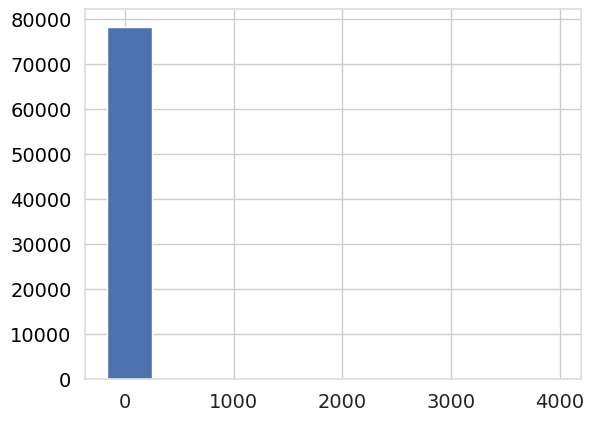

In [ ]:
distribution_differences.differens_paid.hist();

In [ ]:
orders_ordersline_products.groupby("status")["differens_paid"].describe()

,count,mean,std,min,25%,50%,75%,max
status,,,,,,,,
Completed,55228.00,4.36,22.84,-165.00,0.00,4.99,6.99,3984.99
Pending,16468.00,1.99,3.26,-40.00,0.00,0.00,4.99,69.98
Place Order,26898.00,2.07,4.11,-65.99,0.00,0.00,3.99,185.18


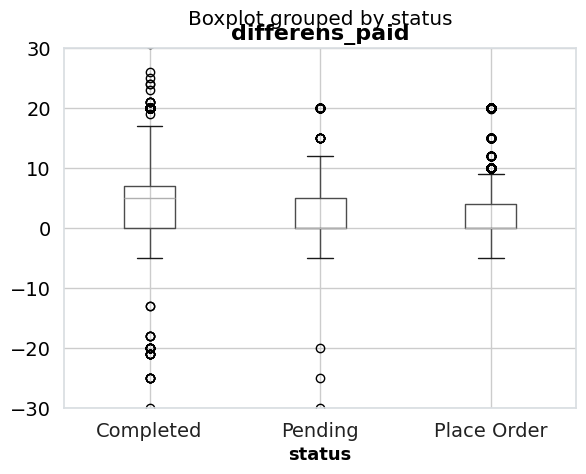

In [ ]:
import matplotlib.pyplot as plt

ax = distribution_differences.boxplot(
    column="differens_paid",
    by="status");
ax.set_ylim(-30, +30)
plt.show()

In [ ]:
# Anhand unserer Quartile von 0,00 €, 4,99 € und 6,99 € sehen wir, dass der größte Teil der Bestelldaten den erwarteten Mustern entspricht.

# Kostenloser Versand oder Versandkosten von 4,99 € bzw. 6,99 € scheinen realistische und nachvollziehbare Preise zu sein.

# Nur die Minimal- und Maximalwerte können die Daten verzerren. Deshalb könnten wir diese Extremwerte für die weitere Analyse ausschließen.

In [ ]:
# calculate the quartiles
Q1 = distribution_differences["differens_paid"].quantile(0.25)
Q3 = distribution_differences["differens_paid"].quantile(0.75)

Q1, Q3

(np.float64(0.0), np.float64(4.990000000000009))

In [ ]:
# calculate the interquartile range
IQR = Q3 - Q1
IQR

np.float64(4.990000000000009)

In [ ]:
# lower boundary
Q1 - 1.5*IQR

np.float64(-7.485000000000014)

In [ ]:
# upper boundary
Q3 + 1.5*IQR

np.float64(12.475000000000023)

In [ ]:
# filter the DataFrame to include only "no-outliers"
diff_no_outliers_df = distribution_differences.loc[
    (distribution_differences["differens_paid"] >= (Q1-1.5*IQR))
    &
    (distribution_differences["differens_paid"] <= (Q1+1.5*IQR))
    , :]

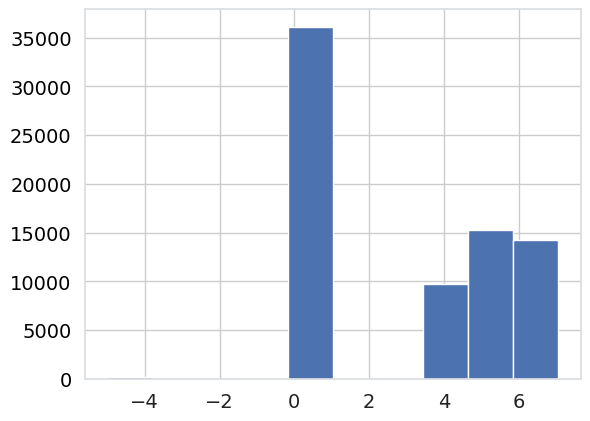

In [ ]:
# quckt noch mal distribution mit quartils effect
diff_no_outliers_df.differens_paid.hist();

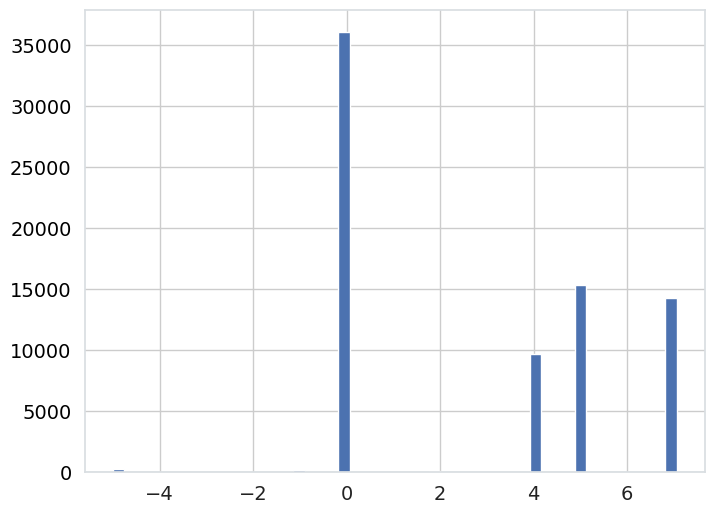

In [ ]:
diff_no_outliers_df.differens_paid.hist(bins=50, figsize=(8,6));

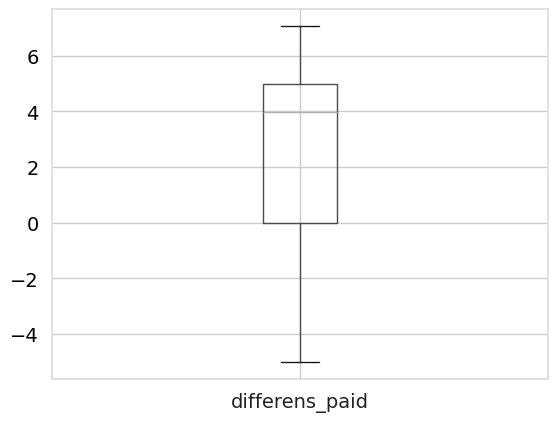

In [ ]:
diff_no_outliers_df.boxplot("differens_paid");

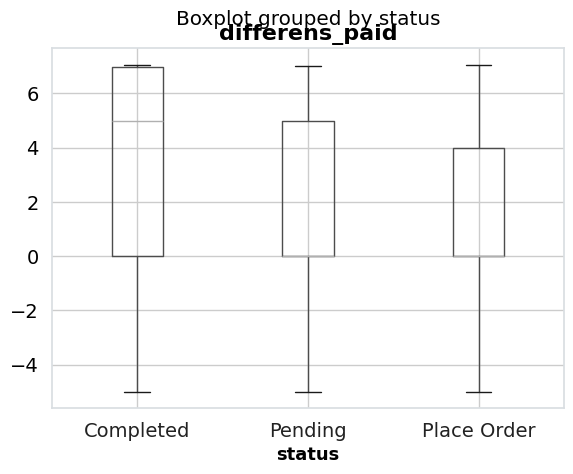

In [ ]:
ax = diff_no_outliers_df.boxplot(
    column="differens_paid",
    by="status");
# ax.set_ylim(-30, +30)
plt.show()

## Analyse

### Time period

In [ ]:
orders_ordersline_products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98594 entries, 0 to 98593
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id_order             98594 non-null  int64  
 1   created_date         98594 non-null  object 
 2   total_paid           98594 non-null  float64
 3   status               98594 non-null  object 
 4   id                   98594 non-null  float64
 5   product_id           98594 non-null  float64
 6   product_quantity     98594 non-null  float64
 7   sku                  98594 non-null  object 
 8   unit_price           98594 non-null  float64
 9   products_paid        98594 non-null  float64
 10  products_paid_total  98594 non-null  float64
 11  differens_paid       98594 non-null  float64
 12  date                 98594 non-null  object 
 13  name                 98594 non-null  object 
 14  desc                 98594 non-null  object 
 15  price                98594 non-null 

In [ ]:
orders_ordersline_products["created_date"] = pd.to_datetime(orders_ordersline_products["created_date"])

In [ ]:
min_date = orders_ordersline_products["created_date"].min()
min_date

Timestamp('2017-01-01 01:51:47')

In [ ]:
max_date = orders_ordersline_products["created_date"].max()
max_date

Timestamp('2018-03-14 13:58:36')

In [ ]:
from dateutil.relativedelta import relativedelta

time_delta = relativedelta(max_date, min_date)
time_delta

relativedelta(years=+1, months=+2, days=+13, hours=+12, minutes=+6, seconds=+49)

### Seasonal patterns

In [ ]:
orders_unique = orders_ordersline_products.drop_duplicates(subset="id_order")

# add columns with year and month
orders_unique["month"] = orders_unique["created_date"].dt.to_period("M")
orders_unique.head(2)

/tmp/ipykernel_836/1696937252.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  orders_unique["month"] = orders_unique["created_date"].dt.to_period("M")


,id_order,created_date,total_paid,status,id,product_id,product_quantity,sku,unit_price,products_paid,products_paid_total,differens_paid,date,name,desc,price,in_stock,type,month
0,241423,2017-11-06 13:10:02,136.15,Completed,1398738.00,0.00,1.00,LAC0212,129.16,129.16,129.16,6.99,2017-11-06 12:47:20,LaCie Porsche Design Desktop Drive 4TB USB 3.0...,External Hard Drive 4TB 35-inch USB 3.0 for Ma...,139.99,1.00,11935397,2017-11
1,242832,2017-12-31 17:40:03,15.76,Completed,1529178.00,0.00,1.00,PAR0074,10.77,10.77,10.77,4.99,2017-12-31 17:26:40,Parrot 550mAh battery for MiniDrones,550mAh rechargeable battery for Parrot minidrones,17.99,0.00,11905404,2017-12


In [ ]:
monthly_sales_status = orders_unique.groupby(["month", "status"])["total_paid"].sum().unstack()
monthly_sales_status.index = monthly_sales_status.index.strftime("%B %Y")
print (monthly_sales_status)

status          Completed   Pending  Place Order
month                                           
January 2017    642318.84  57267.40    394109.91
February 2017   347280.00 191068.82    326831.88
March 2017       24996.80 418055.85    244325.34
April 2017      236557.59 197119.31    237421.85
May 2017        344934.36 155934.51    231970.47
June 2017       303055.21 179586.97    289262.10
July 2017       629733.86  93387.69    340220.65
August 2017     396460.87  65777.74    261576.44
September 2017  406953.08 146112.18    320590.53
October 2017    580154.36  84501.68    407791.85
November 2017  1574871.65 234977.25    951018.14
December 2017  1034143.02 146919.59    765871.31
January 2018    906441.35 138618.12    654367.28
February 2018   568144.58  92503.56    399498.57
March 2018      235333.97  71033.41    178982.82


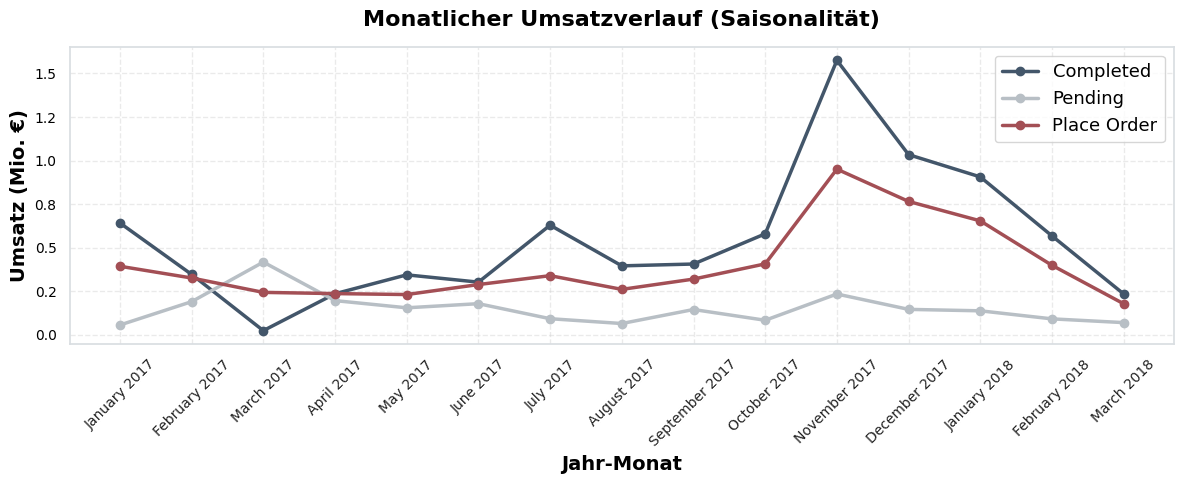

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Grafikgröße
plt.figure(figsize=(12, 5))

# Completed
plt.plot(
    monthly_sales_status.index,
    monthly_sales_status["Completed"],
    label="Completed",
    marker="o",
    markersize=6,
    linewidth=2.5,
    color="#43566A",
    linestyle="-"
)

# Pending
plt.plot(
    monthly_sales_status.index,
    monthly_sales_status["Pending"],
    label="Pending",
    marker="o",
    markersize=6,
    linewidth=2.5,
    color="#B8BFC5",
    linestyle="-"
)

# Place Order
plt.plot(
    monthly_sales_status.index,
    monthly_sales_status["Place Order"],
    label="Place Order",
    marker="o",
    markersize=6,
    linewidth=2.5,
    color="#A34F55",
    linestyle="-"
)

# Achsenbeschriftung
plt.xticks(rotation=45, fontsize=10)
plt.yticks(fontsize=10)

# Werte in Millionen Euro anzeigen
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x / 1_000_000:.1f}")
)

# Titel und Achsentitel
plt.title(
    "Monatlicher Umsatzverlauf (Saisonalität)",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Jahr-Monat", fontsize=14)
plt.ylabel("Umsatz (Mio. €)", fontsize=14)

# Legende
plt.legend(fontsize=13)

# Gitternetz
plt.grid(True, linestyle="--", alpha=0.4)

# Layout
plt.tight_layout()

# Grafik speichern
plt.savefig("monthly_sales.png", dpi=300, bbox_inches="tight")
#plt.savefig(
#    "sales_overview.png",
#    dpi=300,
#    bbox_inches="tight"
#)
plt.show();


In [ ]:
#from google.colab import files

#files.download("sales_overview.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
monthly_sales = orders_unique.groupby("month")["total_paid"].sum()
monthly_sales.index = monthly_sales.index.strftime("%B %Y")
print (monthly_sales)

month
January 2017     1093696.15
February 2017     865180.70
March 2017        687377.99
April 2017        671098.75
May 2017          732839.34
June 2017         771904.28
July 2017        1063342.20
August 2017       723815.05
September 2017    873655.79
October 2017     1072447.89
November 2017    2760867.04
December 2017    1946933.92
January 2018     1699426.75
February 2018    1060146.71
March 2018        485350.20
Name: total_paid, dtype: float64


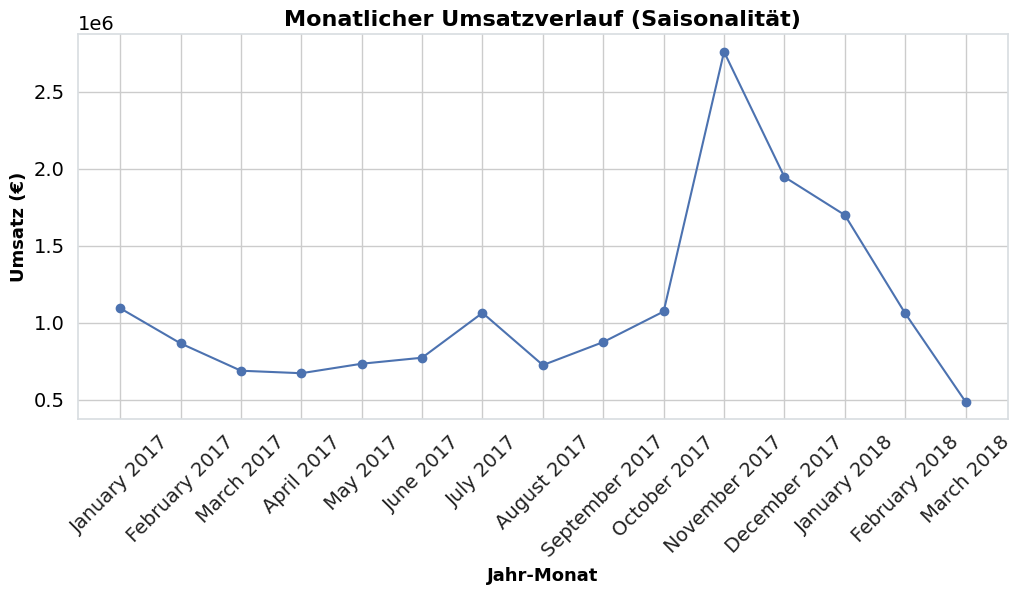

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales.index,
    monthly_sales.values,

    marker="o",
    color= 'b',
    linestyle="-",
)
plt.xticks(rotation=45)
plt.title("Monatlicher Umsatzverlauf (Saisonalität)")
plt.xlabel("Jahr-Monat")
plt.ylabel("Umsatz (€)")
plt.grid(True)
plt.show();

### Products

In [ ]:
# Analyse der Produkte für alle drei Status: Completed, Pending, Place Order.

# Wenn wir weiterhin nur Informationen zu einem bestimmten Status sehen möchten, müssen wir diesen Status direkt auswählen.
# vor .groupby darauf hinweisen ->
# .loc[orders_ordersline_products["status"] == "Completed"]

product_analysis = orders_ordersline_products.groupby("sku").agg(
    name=("name", "first"),
    id_order_quantity=("id_order", "nunique"),
    total_quantity=("product_quantity", "sum"),
    total_products_paid=("products_paid", "sum"),
    min_price=("unit_price", "min"),
    max_price=("unit_price", "max"),
    average_price=("unit_price", "mean")
).reset_index()

product_analysis.head(10)


,sku,name,id_order_quantity,total_quantity,total_products_paid,min_price,max_price,average_price
0,8MO0001-A,Open - Micro SD Adapter 8Mobility iSlice Macbo...,1,1.00,12.96,12.96,12.96,12.96
1,8MO0003-A,Open - 8Mobility iSlice Micro SD adapter for M...,1,1.00,12.85,12.85,12.85,12.85
2,8MO0007,8Mobility iSlice Micro SD adapter for Macbook ...,9,9.00,195.91,19.99,23.99,21.77
3,8MO0008,8Mobility iSlice Micro SD Adapter Macbook Pro ...,13,14.00,299.86,19.99,23.99,21.53
4,8MO0009,8Mobility iSlice Micro SD Adapter for Macbook ...,9,9.00,169.33,14.70,23.99,18.81
5,8MO0010,8Mobility iSlice Micro SD Adapter for MacBook ...,2,2.00,33.98,16.99,16.99,16.99
6,8MO0011,8Mobility iSlice Micro SD Adapter MacBook Pro ...,10,11.00,222.89,18.99,23.99,20.29
7,8MO0012,8Mobility iSlice Micro SD Adapter MacBook Pro ...,4,4.00,62.96,12.99,23.99,15.74
8,ACM0009,"Acme Skinny Sleeve Case MacBook Air 11 ""Black",1,1.00,23.99,23.99,23.99,23.99
9,ADN0016-A,Open - Adonit Jot Touch with PixelPoint pointe...,2,2.00,76.16,38.08,38.08,38.08


products that generate the most revenue

In [ ]:
# analysis by number of orders
product_analysis = product_analysis.sort_values(by="id_order_quantity", ascending=False)

product_analysis.head(10)

,sku,name,id_order_quantity,total_quantity,total_products_paid,min_price,max_price,average_price
511,APP1190,IPhone AppleCare Protection Plan,1793,1946.00,107104.59,42.15,70.00,55.03
406,APP0698,Apple Lightning Cable Connector to USB 1m Whit...,873,1368.00,13701.58,3.33,14.99,10.05
757,APP1922,AirPods Apple Bluetooth Headset for iPhone iPa...,803,837.00,134834.53,127.27,179.00,161.14
429,APP0927,EarPods Apple Headphones with Remote and Mic (...,731,917.00,15465.83,12.39,23.99,16.97
4576,SAM0074,Samsung 850 EVO SSD Disk 500GB,571,616.00,94151.56,122.89,169.99,152.77
5701,WDT0183,"Red 4TB WD 35 ""Mac PC hard drive and NAS",562,870.00,120180.15,63.50,164.99,138.28
1463,CRU0051,Crucial MX300 525GB SSD Disk,475,575.00,79557.73,100.75,168.99,138.76
528,APP1214,Apple Magic Mouse 2,450,474.00,38291.49,63.59,89.00,80.76
772,APP1970,Apple iPhone 32GB Space Gray,427,435.00,156889.46,288.43,489.00,360.72
957,APP2485,Apple iPhone 8 Plus 64GB Gold,400,405.00,359226.48,728.14,917.33,886.78


In [ ]:
# analysis by number of units sold
product_analysis = product_analysis.sort_values(by="total_quantity", ascending=False)

product_analysis.head(10)

,sku,name,id_order_quantity,total_quantity,total_products_paid,min_price,max_price,average_price
511,APP1190,IPhone AppleCare Protection Plan,1793,1946.00,107104.59,42.15,70.00,55.03
406,APP0698,Apple Lightning Cable Connector to USB 1m Whit...,873,1368.00,13701.58,3.33,14.99,10.05
429,APP0927,EarPods Apple Headphones with Remote and Mic (...,731,917.00,15465.83,12.39,23.99,16.97
5701,WDT0183,"Red 4TB WD 35 ""Mac PC hard drive and NAS",562,870.00,120180.15,63.50,164.99,138.28
757,APP1922,AirPods Apple Bluetooth Headset for iPhone iPa...,803,837.00,134834.53,127.27,179.00,161.14
2519,KIN0137,Kingston Memory Card microSDHC UHS Class 1 | 1...,12,815.00,6099.76,4.99,9.28,7.32
4576,SAM0074,Samsung 850 EVO SSD Disk 500GB,571,616.00,94151.56,122.89,169.99,152.77
1463,CRU0051,Crucial MX300 525GB SSD Disk,475,575.00,79557.73,100.75,168.99,138.76
5697,WDT0141,"WD Red 3TB 35 ""Mac PC hard drive and NAS",308,481.00,52328.69,88.71,124.99,108.82
3359,NTE0013,"AdaptaDrive NewerTech adapter 2.5 ""to 3.5"" SATA",376,475.00,8873.32,1.00,19.99,19.40


In [ ]:
# analysis of revenue by product
product_analysis = product_analysis.sort_values(by="total_products_paid", ascending=False)

product_analysis.head(10)

,sku,name,id_order_quantity,total_quantity,total_products_paid,min_price,max_price,average_price
957,APP2485,Apple iPhone 8 Plus 64GB Gold,400,405.00,359226.48,728.14,917.33,886.78
947,APP2477,Apple iPhone 64GB Space Gray 8,317,330.00,258928.48,642.29,807.33,784.35
955,APP2483,Apple iPhone 8 Plus 64GB Space Gray,275,286.00,254436.50,670.52,917.33,888.96
843,APP2072,"Apple MacBook Air 13 ""Core i5 18GHz | 8GB RAM ...",236,237.00,229000.58,800.83,995.59,966.32
2757,LGE0044,"LG 27UD88-W Monitor 27 ""UHD 4K USB 3.0 USB-C",316,383.00,217322.03,440.80,599.99,567.67
956,APP2484,Apple iPhone 8 Plus 64GB Silver,184,188.00,167270.62,728.14,917.33,889.44
950,APP2479,Apple iPhone 64GB Gold 8,208,209.00,165157.74,667.22,807.33,790.22
772,APP1970,Apple iPhone 32GB Space Gray,427,435.00,156889.46,288.43,489.00,360.72
757,APP1922,AirPods Apple Bluetooth Headset for iPhone iPa...,803,837.00,134834.53,127.27,179.00,161.14
928,APP2446,Apple iPhone 6 32GB Space Gray,325,342.00,132461.06,322.59,390.33,387.28


### Rabatt

In [ ]:
# Rabatt-Spalte berechnen (regulärer Produktpreis minus tatsächlicher Einzelpreis)
orders_ordersline_products["discount"] = (orders_ordersline_products["price"] - orders_ordersline_products["unit_price"]) / orders_ordersline_products["price"] * 100

orders_ordersline_products.head(2)

,id_order,created_date,total_paid,status,id,product_id,product_quantity,sku,unit_price,products_paid,products_paid_total,differens_paid,date,name,desc,price,in_stock,type,discount
0,241423,2017-11-06 13:10:02,136.15,Completed,1398738.00,0.00,1.00,LAC0212,129.16,129.16,129.16,6.99,2017-11-06 12:47:20,LaCie Porsche Design Desktop Drive 4TB USB 3.0...,External Hard Drive 4TB 35-inch USB 3.0 for Ma...,139.99,1.00,11935397,7.74
1,242832,2017-12-31 17:40:03,15.76,Completed,1529178.00,0.00,1.00,PAR0074,10.77,10.77,10.77,4.99,2017-12-31 17:26:40,Parrot 550mAh battery for MiniDrones,550mAh rechargeable battery for Parrot minidrones,17.99,0.00,11905404,40.13


In [ ]:
orders_ordersline_products["discount"].describe()

,discount
count,98594.00
mean,20.41
std,21.24
min,-3146.49
25%,7.83
50%,16.72
75%,27.45
max,97.71


In [ ]:
orders_ordersline_products.groupby("status")["discount"].describe()

,count,mean,std,min,25%,50%,75%,max
status,,,,,,,,
Completed,55228.00,22.04,18.96,-212.27,9.41,18.04,29.36,97.71
Pending,16468.00,22.07,19.96,-212.27,8.89,17.52,29.97,97.45
Place Order,26898.00,16.05,25.42,-3146.49,4.51,14.19,23.17,93.34


In [ ]:
orders_ordersline_products["month"] = orders_ordersline_products["created_date"].dt.to_period("M")
orders_ordersline_products.head(2)

,id_order,created_date,total_paid,status,id,product_id,product_quantity,sku,unit_price,products_paid,products_paid_total,differens_paid,date,name,desc,price,in_stock,type,discount,month
0,241423,2017-11-06 13:10:02,136.15,Completed,1398738.00,0.00,1.00,LAC0212,129.16,129.16,129.16,6.99,2017-11-06 12:47:20,LaCie Porsche Design Desktop Drive 4TB USB 3.0...,External Hard Drive 4TB 35-inch USB 3.0 for Ma...,139.99,1.00,11935397,7.74,2017-11
1,242832,2017-12-31 17:40:03,15.76,Completed,1529178.00,0.00,1.00,PAR0074,10.77,10.77,10.77,4.99,2017-12-31 17:26:40,Parrot 550mAh battery for MiniDrones,550mAh rechargeable battery for Parrot minidrones,17.99,0.00,11905404,40.13,2017-12


In [ ]:
monthly_discount = orders_ordersline_products[orders_ordersline_products["status"] == "Completed"].groupby("month")["discount"].describe()
monthly_discount

,count,mean,std,min,25%,50%,75%,max
month,,,,,,,,
2017-01,6202.00,25.35,21.42,-50.01,10.00,20.99,35.73,93.30
2017-02,2668.00,19.80,17.76,-61.34,8.51,17.43,27.54,92.15
2017-03,216.00,19.38,20.73,-40.00,3.38,16.54,30.02,90.00
2017-04,1946.00,18.96,18.48,-212.27,6.68,16.54,26.47,91.94
2017-05,2240.00,16.35,17.10,-45.85,5.10,13.33,22.22,92.93
2017-06,1826.00,17.99,16.93,-45.85,6.61,15.56,25.01,92.04
2017-07,4301.00,25.35,20.89,-212.27,11.34,19.94,36.95,93.34
2017-08,2800.00,21.17,19.30,-212.27,9.10,16.67,27.79,92.55
2017-09,2558.00,20.62,19.02,-50.01,7.92,16.36,26.35,91.94


In [ ]:
# Kopie der Daten erstellen
discount_df = orders_ordersline_products.copy()


# Rabattgruppen erstellen
discount_df["discount_group"] = pd.cut(
    discount_df["discount"],
    bins=[-0.01, 0.01, 5, 10, 20, 100],
    labels=["0%", "0-5%", "5-10%", "10-20%", ">20%"]
)

# Analyse nach Rabattgruppen
discount_analysis = discount_df.groupby(
    "discount_group",
    observed=True
).agg(
    total_quantity=("product_quantity", "sum"),
    avg_quantity=("product_quantity", "mean"),
    avg_discount=("discount", "mean"),
    order_lines=("sku", "count")
).reset_index()

display(discount_analysis)

,discount_group,total_quantity,avg_quantity,avg_discount,order_lines
0,0%,5247.00,1.11,-0.00,4731
1,0-5%,10493.00,1.09,2.70,9644
2,5-10%,12891.00,1.13,7.37,11430
3,10-20%,31736.00,1.14,14.86,27767
4,>20%,46554.00,1.12,36.72,41463


### Durchschnittlicher Bestellwert (AOV)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
import matplotlib.ticker as mticker

completed_df = orders_ordersline_products.copy()

if "status" in completed_df.columns:
    completed_df = completed_df[
        completed_df["status"] == "Completed"
    ].copy()

completed_df.head(2)

,id_order,created_date,total_paid,status,id,product_id,product_quantity,sku,unit_price,products_paid,products_paid_total,differens_paid,date,name,desc,price,in_stock,type,discount,month
0,241423,2017-11-06 13:10:02,136.15,Completed,1398738.00,0.00,1.00,LAC0212,129.16,129.16,129.16,6.99,2017-11-06 12:47:20,LaCie Porsche Design Desktop Drive 4TB USB 3.0...,External Hard Drive 4TB 35-inch USB 3.0 for Ma...,139.99,1.00,11935397,7.74,2017-11
1,242832,2017-12-31 17:40:03,15.76,Completed,1529178.00,0.00,1.00,PAR0074,10.77,10.77,10.77,4.99,2017-12-31 17:26:40,Parrot 550mAh battery for MiniDrones,550mAh rechargeable battery for Parrot minidrones,17.99,0.00,11905404,40.13,2017-12


In [ ]:
# DataFrame mit unique Bestelungen
orders_completed = (
    completed_df[
        ["id_order", "total_paid", "month"]
    ]
    .drop_duplicates(subset="id_order")
    .copy()
)

orders_completed.head()

,id_order,total_paid,month
0,241423,136.15,2017-11
1,242832,15.76,2017-12
2,243330,84.98,2017-02
3,245275,149.00,2017-06
4,245595,112.97,2017-01


In [ ]:
# gruppieren die Bestellungen nach Monaten
aov_by_month = (
    orders_completed
    .groupby("month")
    .agg(
        orders_count=("id_order", "nunique"),
        total_revenue=("total_paid", "sum"),
        average_order_value=("total_paid", "mean")
    )
    .reset_index())

aov_by_month["month"] = (
  aov_by_month["month"].dt.to_timestamp()
)

aov_by_month

,month,orders_count,total_revenue,average_order_value
0,2017-01-01,4728,642318.84,135.85
1,2017-02-01,2078,347280.00,167.12
2,2017-03-01,164,24996.80,152.42
3,2017-04-01,1494,236557.59,158.34
4,2017-05-01,1710,344934.36,201.72
5,2017-06-01,1387,303055.21,218.50
6,2017-07-01,3163,629733.86,199.09
7,2017-08-01,2160,396460.87,183.55
8,2017-09-01,1927,406953.08,211.18
9,2017-10-01,2853,580154.36,203.35


In [ ]:
orders_completed.dtypes

,0
id_order,int64
total_paid,float64
month,period[M]


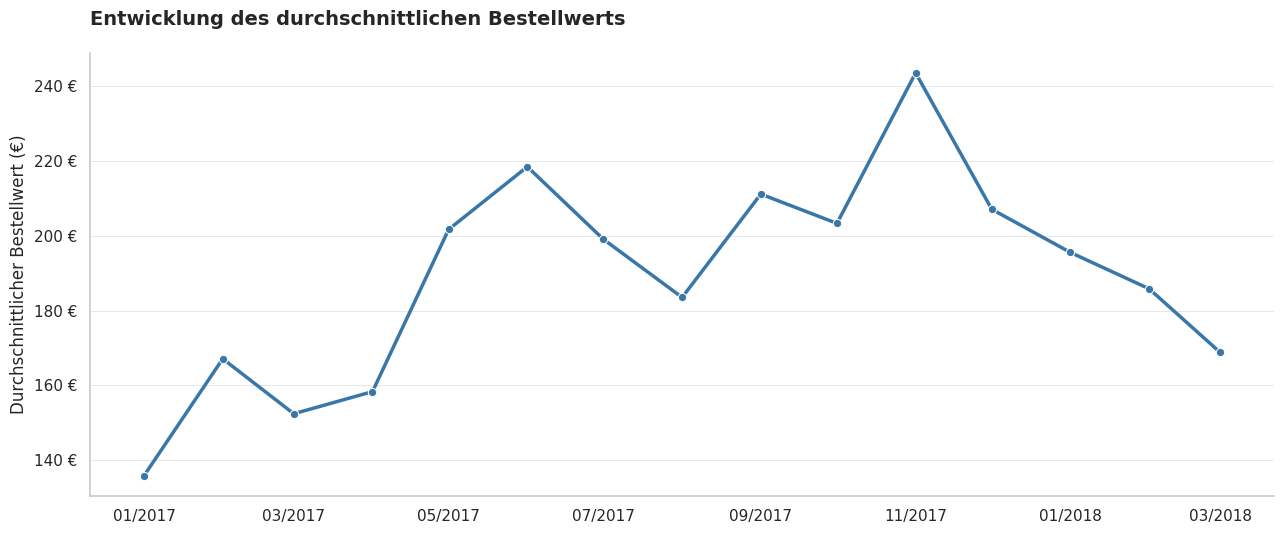

In [ ]:
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(13, 5.5))

sns.lineplot(
    data=aov_by_month,
    x="month",
    y="average_order_value",
    color="#3977A8",
    linewidth=2.5,
    marker="o",
    markersize=6,
    ax=ax
)

ax.set_title(
    "Entwicklung des durchschnittlichen Bestellwerts",
    loc="left",
    pad=20,
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("")
ax.set_ylabel("Durchschnittlicher Bestellwert (€)")

ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{x:,.0f} €")
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%m/%Y")
)

ax.grid(axis="y", color="#E5E7EB", linewidth=0.7)
ax.grid(axis="x", visible=False)

sns.despine()

plt.tight_layout()
plt.show()

# Product Categories

In [ ]:
# Klassifizierungsfunktion
# macht new funktion

def category_products(row):

  # Datenaufbereitung, Umwandlung aller Buchstaben in Kleinbuchstaben
  name = row["name"].lower()
  desc = row["desc"].lower()

  # Apple devices
  if "iphone" in name and not any(x in name for x in ["case", "cover", "battery", "charger", "cable"]):
    return "iPhone"

  elif "ipad" in name and not any(x in name for x in ["case", "cover", "keyboard", "charger", "cable"]):
    return "iPad"

  elif any(x in name for x in ["ipod", "apple tv", "apple watch"]):
    return "Apple Devices"

  # Mac computers
  elif any(x in name for x in ["macbook", "imac", "mac mini", "mac pro"]) and not any(x in name for x in ["case", "cover", "battery", "charger", "memory", "ssd", "kit", "adapter"]):
    return "Mac Computers"

  # Accessories and components
  elif any(x in name for x in ["case", "cover", "protector", "sleeve"]):
    return "Cases & Protection"

  elif any(x in name for x in ["cable", "adapter", "hub", "charger", "battery", "power bank"]):
    return "Electronic Accessories"

  elif any(x in name for x in ["hard drive", "ssd", "nas"]):
    return "Storage"

  elif any(x in name for x in ["memory", "ram", "microsd", "sdxc"]):
    return "Memory"

  elif any(x in name for x in ["headphone", "earpods", "speaker", "microphone"]):
    return "Audio"

  elif "monitor" in name:
    return "Monitors"

  elif any(x in name for x in ["keyboard", "mouse", "trackpad", "stand", "dock", "holder", "support"]):
    return "Computer Accessories"

  elif any(x in name for x in ["router", "switch", "network"]):
    return "Networking"

  elif any(x in name for x in ["tool", "screwdriver", "repair"]):
    return "Tools & Repair"

  else:
    return "Other"


In [ ]:
# wenden die Funktion auf unsere Tabelle an und fügen eine neue Spalte hinzu
orders_ordersline_products["category"] = orders_ordersline_products.apply(category_products, axis=1)

orders_ordersline_products.tail(2)

,id_order,created_date,total_paid,status,id,product_id,product_quantity,sku,unit_price,products_paid,...,differens_paid,date,name,desc,price,in_stock,type,discount,month,category
98592,527397,2018-03-14 13:56:38,42.99,Place Order,1650198.00,0.00,1.00,JBL0122,42.99,42.99,...,0.00,2018-03-14 13:56:38,JBL T450 BT Bluetooth Headset Black,Wireless headphones with folding design with 1...,49.95,1.00,5384,13.93,2018-03,Other
98593,527401,2018-03-14 13:58:36,18.98,Place Order,1650203.00,0.00,1.00,APP0927,13.99,13.99,...,4.99,2018-03-14 13:58:36,EarPods Apple Headphones with Remote and Mic (...,EarPods headphones Apple iPhone iPad and iPod ...,35.00,1.00,5384,60.03,2018-03,Audio


In [ ]:
orders_ordersline_products.groupby("category")["products_paid"].describe()

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Apple Devices,3373.00,188.99,178.64,2.54,22.79,79.99,383.04,1638.00
Audio,3323.00,141.50,157.12,8.99,23.74,89.99,212.43,1395.00
Cases & Protection,11804.00,37.64,48.57,2.31,16.99,29.99,40.85,1484.73
Computer Accessories,3518.00,92.22,97.34,5.99,38.24,77.28,109.99,3239.73
Electronic Accessories,13708.00,45.04,43.78,2.47,16.99,31.34,65.90,1019.83
Mac Computers,3505.00,148.52,246.70,4.24,24.99,49.99,138.00,3815.94
Memory,6256.00,133.44,156.04,4.49,67.99,89.98,149.99,5992.00
Monitors,2888.00,378.44,414.79,24.20,164.90,291.39,554.01,8959.86
Networking,974.00,173.47,191.95,6.36,35.98,84.66,255.99,1272.36


In [ ]:
orders_ordersline_products["category"].value_counts()

,count
category,
Other,18605
Storage,14573
Electronic Accessories,13708
iPhone,13099
Cases & Protection,11804
Memory,6256
Computer Accessories,3518
Mac Computers,3505
Apple Devices,3373


In [ ]:
category_analysis = orders_ordersline_products.groupby("category").agg(
    count=("category", "size"),
    total_quantity=("product_quantity", "sum"),
    products_paid=("products_paid", "sum")
).sort_values(by="products_paid", ascending=False)

category_analysis

,count,total_quantity,products_paid
category,,,
iPhone,13099,13743.00,4273455.70
Storage,14573,17109.00,3532355.18
Other,18605,21390.00,2278028.69
Monitors,2888,3318.00,1092921.68
iPad,2362,2529.00,1039273.33
Memory,6256,8495.00,834808.78
Apple Devices,3373,3511.00,637450.27
Electronic Accessories,13708,15516.00,617396.99
Mac Computers,3505,3652.00,520579.53


In [ ]:
category_status = orders_ordersline_products.groupby(["category", "status"]).size().unstack(fill_value=0)

# size() - count rows, not quatuty

category_status = category_status.sort_values(by="Completed", ascending=False)
category_status

status,Completed,Pending,Place Order
category,,,
Other,10500,3165,4940
Electronic Accessories,8203,2603,2902
Storage,8082,2569,3922
Cases & Protection,6665,1994,3145
iPhone,6377,1767,4955
Memory,3627,1148,1481
Computer Accessories,2285,609,624
Mac Computers,2122,658,725
Audio,1926,561,836


## Bilden die Diagram

In [ ]:
# wählen nur Completed aus
completed_df = orders_ordersline_products[orders_ordersline_products["status"] == "Completed"]

# category zusammenfassen
category_completed = completed_df.groupby("category").agg(
    total_quantity=("product_quantity","sum"),
    total_umsatz=("products_paid","sum")
).reset_index()
category_completed

,category,total_quantity,total_umsatz
0,Apple Devices,1813.00,267501.68
1,Audio,2161.00,273131.12
2,Cases & Protection,7025.00,236312.46
3,Computer Accessories,2539.00,208946.65
4,Electronic Accessories,9428.00,378687.01
5,Mac Computers,2222.00,271438.26
6,Memory,4475.00,475587.53
7,Monitors,1974.00,641335.96
8,Networking,645.00,91812.36
9,Other,12157.00,1240153.68


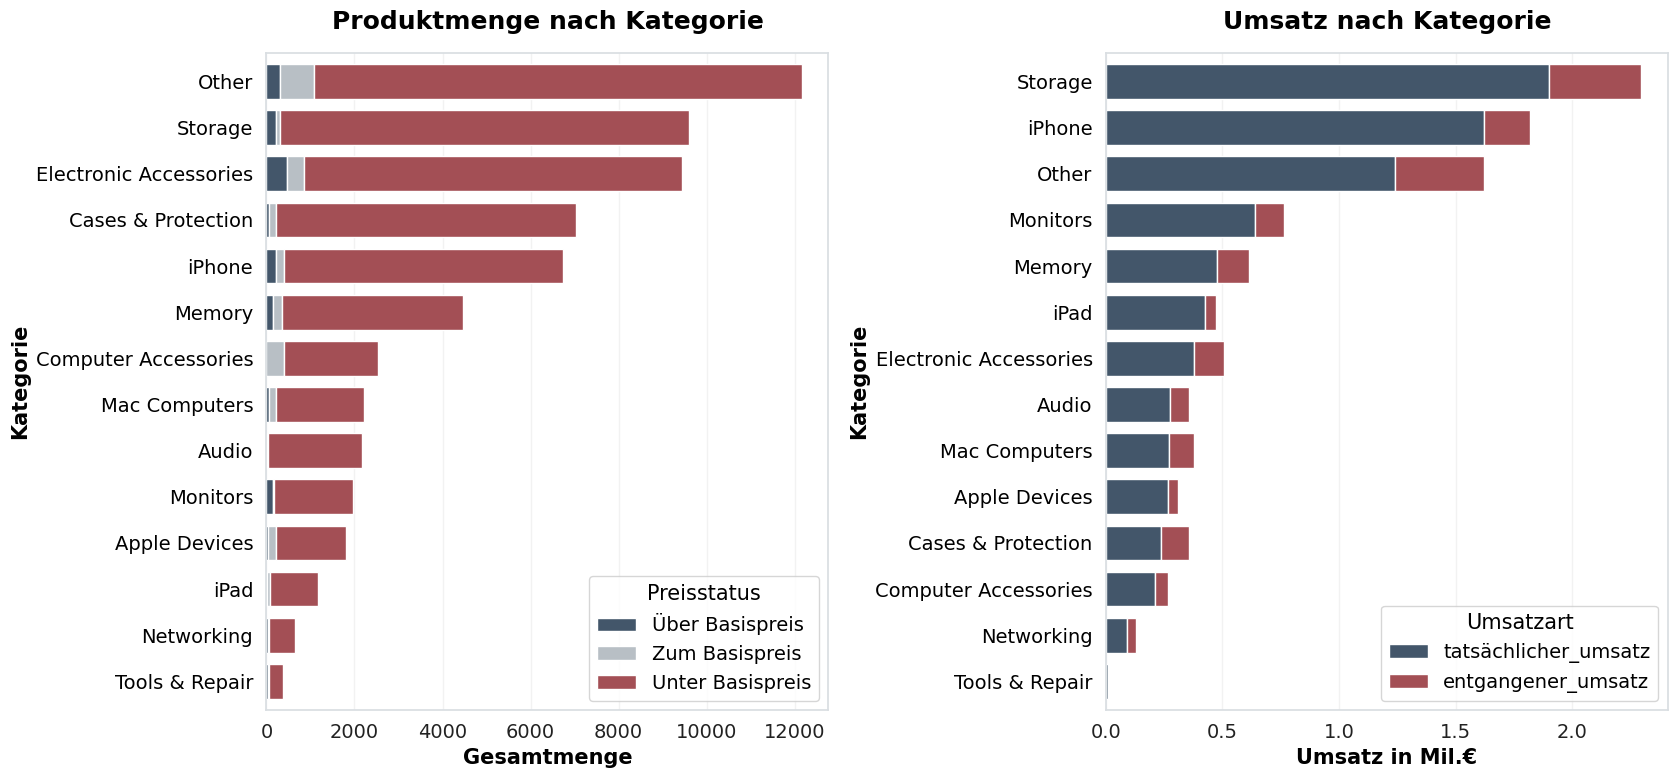

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 14,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.titlecolor": "#000000",
    "axes.labelsize": 15,
    "axes.labelweight": "semibold",
    "axes.labelcolor": "#000000",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#D9DEE2",
    "text.color": "#000000",
    "xtick.color": "#222222",
    "ytick.color": "#000000",
    "xtick.labelsize": 14,
    "ytick.labelsize": 14
})

# Kopie der Daten
df = orders_ordersline_products.copy()

# Nur abgeschlossene Bestellungen
df = df[df["status"] == "Completed"].copy()

# Numerische Werte vorbereiten
for col in ["price", "unit_price", "product_quantity"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Fehlende Werte entfernen
df = df.dropna(
    subset=["category", "price", "unit_price", "product_quantity"]
)

# Nur gültige Preise und Mengen
df = df[
    (df["price"] > 0) &
    (df["unit_price"] >= 0) &
    (df["product_quantity"] > 0)
].copy()

# Preisstatus bestimmen
tolerance = 0.01

df["price_status"] = np.select(
    [
        df["unit_price"] > df["price"] + tolerance,
        df["unit_price"] < df["price"] - tolerance
    ],
    [
        "Über Basispreis",
        "Unter Basispreis"
    ],
    default="Zum Basispreis"
)

# Tatsächlichen Umsatz berechnen
df["total_umsatz"] = (
    df["unit_price"] * df["product_quantity"]
)

# Potenziell entgangenen Umsatz berechnen
df["entgangener_umsatz"] = (
    (df["price"] - df["unit_price"]).clip(lower=0)
    * df["product_quantity"]
)

# Gruppierung nach Kategorie und Preisstatus
quantity_pivot = pd.pivot_table(
    df,
    index="category",
    columns="price_status",
    values="product_quantity",
    aggfunc="sum",
    fill_value=0
)

# Reihenfolge der Preisgruppen
quantity_pivot = quantity_pivot.reindex(
    columns=[
        "Über Basispreis",
        "Zum Basispreis",
        "Unter Basispreis"
    ],
    fill_value=0
)

# Nach Gesamtmenge sortieren
quantity_pivot = quantity_pivot.loc[
    quantity_pivot.sum(axis=1).sort_values(
        ascending=False
    ).index
]

# Umsatz nach Kategorie gruppieren
revenue_pivot = df.groupby("category").agg(
    tatsächlicher_umsatz=("total_umsatz", "sum"),
    entgangener_umsatz=("entgangener_umsatz", "sum")
)

# Nach tatsächlichem Umsatz sortieren
revenue_pivot = revenue_pivot.sort_values(
    by="tatsächlicher_umsatz",
    ascending=False
)

# Diagramme nebeneinander
fig, axes = plt.subplots(1, 2, figsize=(17, 8))

# --------------------------------
# Diagramm 1: Produktmenge
# --------------------------------

quantity_pivot.plot(
    kind="barh",
    stacked=True,
    ax=axes[0],
    color=["#43566A", "#B8BFC5", "#A34F55"],
    width=0.75
)

axes[0].set_title(
    "Produktmenge nach Kategorie",
    fontsize=18,
    pad=17
)

axes[0].set_xlabel("Gesamtmenge")
axes[0].set_ylabel("Kategorie")

axes[0].invert_yaxis()

axes[0].legend(
    title="Preisstatus",
    loc="lower right",
    fontsize=14,
    title_fontsize=15
)

axes[0].grid(axis="x", alpha=0.25)
axes[0].grid(axis="y", visible=False)


# --------------------------------
# Diagramm 2: Umsatz
# --------------------------------

revenue_pivot.plot(
    kind="barh",
    stacked=True,
    ax=axes[1],
    color=["#43566A", "#A34F55"],
    width=0.75
)

axes[1].set_title(
    "Umsatz nach Kategorie",
    fontsize=18,
    pad=17
)

axes[1].set_xlabel("Umsatz in Mil.€")
axes[1].set_ylabel("Kategorie")

axes[1].invert_yaxis()

axes[1].legend(
    title="Umsatzart",
    loc="lower right",
    fontsize=14,
    title_fontsize=15
)

axes[1].grid(axis="x", alpha=0.25)
axes[1].grid(axis="y", visible=False)

# Grafik speichern
#plt.savefig("kategory.png", dpi=300, bbox_inches="tight")


plt.tight_layout()
fig.canvas.draw()
axes[1].xaxis.get_offset_text().set_visible(False)
#plt.savefig(
#    "category_analysis.png",
#    dpi=300,
#    bbox_inches="tight"
#)
plt.show()

In [ ]:
#from google.colab import files

#files.download("category_analysis.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

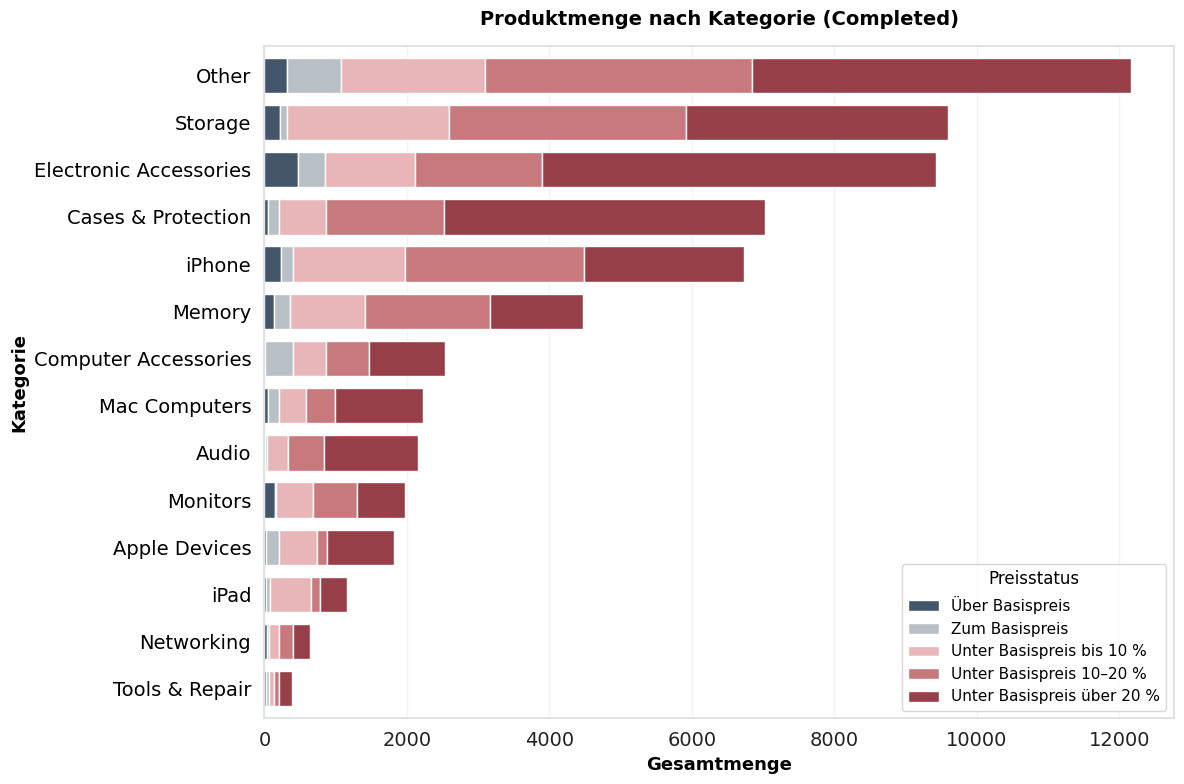

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 13,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#D9DEE2",
    "text.color": "#000000",
    "axes.labelcolor": "#000000",
    "xtick.color": "#222222",
    "ytick.color": "#000000"
})

# Kopie der Daten
df = orders_ordersline_products.copy()

# Nur abgeschlossene Bestellungen
df = df[df["status"] == "Completed"].copy()

# Numerische Werte vorbereiten
for col in ["price", "unit_price", "product_quantity"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Fehlende Werte entfernen
df = df.dropna(
    subset=["category", "price", "unit_price", "product_quantity"]
)

# Nur gültige Preise und Mengen
df = df[
    (df["price"] > 0) &
    (df["unit_price"] >= 0) &
    (df["product_quantity"] > 0)
].copy()


# Rabatt in Prozent berechnen
df["rabatt_prozent"] = (
    (df["price"] - df["unit_price"])
    / df["price"] * 100
)


# Preisstatus bestimmen
tolerance = 0.01

df["price_status"] = np.select(
    [
        df["unit_price"] > df["price"] + tolerance,
        df["unit_price"] < df["price"] - tolerance
    ],
    [
        "Über Basispreis",
        "Unter Basispreis"
    ],
    default="Zum Basispreis"
)


# Unter Basispreis in Rabattstufen aufteilen
mask = df["price_status"] == "Unter Basispreis"

df.loc[mask, "price_status"] = np.select(
    [
        df.loc[mask, "rabatt_prozent"] <= 10,
        df.loc[mask, "rabatt_prozent"] <= 20
    ],
    [
        "Unter Basispreis bis 10 %",
        "Unter Basispreis 10–20 %"
    ],
    default="Unter Basispreis über 20 %"
)


# Gruppierung nach Kategorie und Preisstatus
quantity_pivot = pd.pivot_table(
    df,
    index="category",
    columns="price_status",
    values="product_quantity",
    aggfunc="sum",
    fill_value=0
)


# Reihenfolge der Preisgruppen
quantity_pivot = quantity_pivot.reindex(
    columns=[
        "Über Basispreis",
        "Zum Basispreis",
        "Unter Basispreis bis 10 %",
        "Unter Basispreis 10–20 %",
        "Unter Basispreis über 20 %"
    ],
    fill_value=0
)


# Nach Gesamtmenge sortieren
quantity_pivot = quantity_pivot.loc[
    quantity_pivot.sum(axis=1).sort_values(
        ascending=False
    ).index
]


# --------------------------------
# Diagramm: Produktmenge
# --------------------------------

fig, ax = plt.subplots(figsize=(12, 8))

quantity_pivot.plot(
    kind="barh",
    stacked=True,
    ax=ax,
    color=[
        "#43566A",  # Über Basispreis
        "#B8BFC5",  # Zum Basispreis
        "#E8B6B8",  # Rabatt bis 10 %
        "#C8797D",  # Rabatt 10–20 %
        "#963F48"   # Rabatt über 20 %
    ],
    width=0.75
)

ax.set_title(
    "Produktmenge nach Kategorie (Completed)",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Gesamtmenge")
ax.set_ylabel("Kategorie")

ax.invert_yaxis()

ax.legend(
    title="Preisstatus",
    loc="lower right"
)

ax.grid(axis="x", alpha=0.25)
ax.grid(axis="y", visible=False)

plt.tight_layout()
#plt.savefig(
#    "discount_analysis.png",
#    dpi=300,
#    bbox_inches="tight"
#)

plt.show()


In [ ]:
#from google.colab import files

#files.download("discount_analysis.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#04 Data Visualization

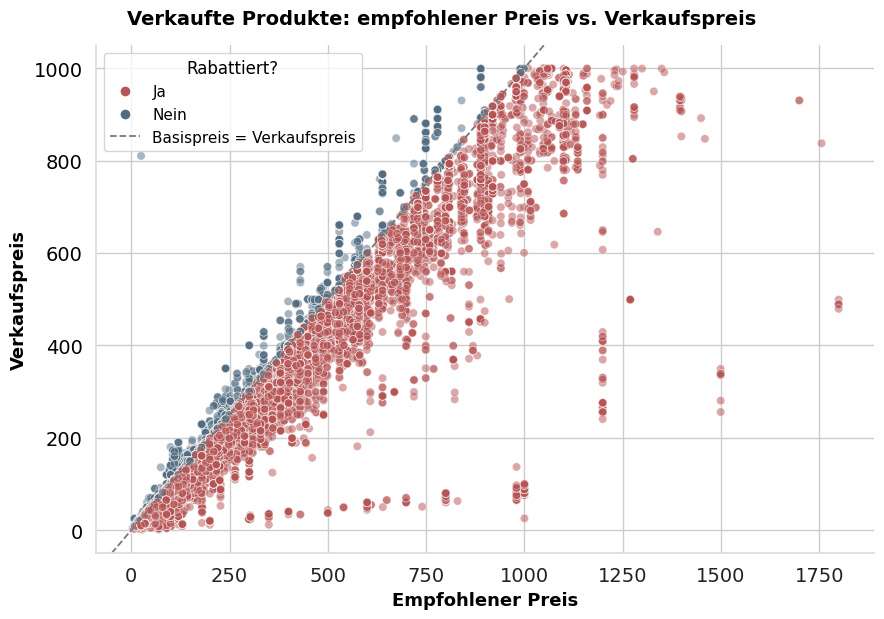

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# 1. Markieren, ob ein Produkt rabattiert wurde
orders_ordersline_products["Rabattiert"] = (
    orders_ordersline_products["unit_price"] <
    orders_ordersline_products["price"]
)

# 2. Scatterplot erstellen
g = sns.relplot(
    data=orders_ordersline_products,
    x="price",
    y="unit_price",
    hue="Rabattiert",
    palette={
        True: "#B65353",
        False: "#526D82"
    },
    alpha=0.5,
    height=6,
    aspect=1.5,
    legend=False
)

# 3. Referenzlinie
g.ax.axline(
    (0, 0),
    slope=1,
    color="#777777",
    linestyle="--",
    linewidth=1.3
)

# 4. Eigene Legende erstellen
legend_elements = [
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='#B65353', markersize=8,
           label='Ja'),
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='#526D82', markersize=8,
           label='Nein'),
    Line2D([0], [0], color='#777777',
           linestyle='--', linewidth=1.3,
           label='Basispreis = Verkaufspreis')
]

g.ax.legend(
    handles=legend_elements,
    title="Rabattiert?",
    loc="upper left"
)

# 5. Titel und Achsenbeschriftungen
g.set_axis_labels(
    "Empfohlener Preis",
    "Verkaufspreis"
)

g.fig.suptitle(
    "Verkaufte Produkte: empfohlener Preis vs. Verkaufspreis",
    fontsize=14,
    fontweight="bold",
    y=1.03
)

plt.show()


,created_date,total_paid
0,2017-01-01,170.96
1,2017-02-01,221.93
2,2017-03-01,193.13
3,2017-04-01,206.16
4,2017-05-01,219.75


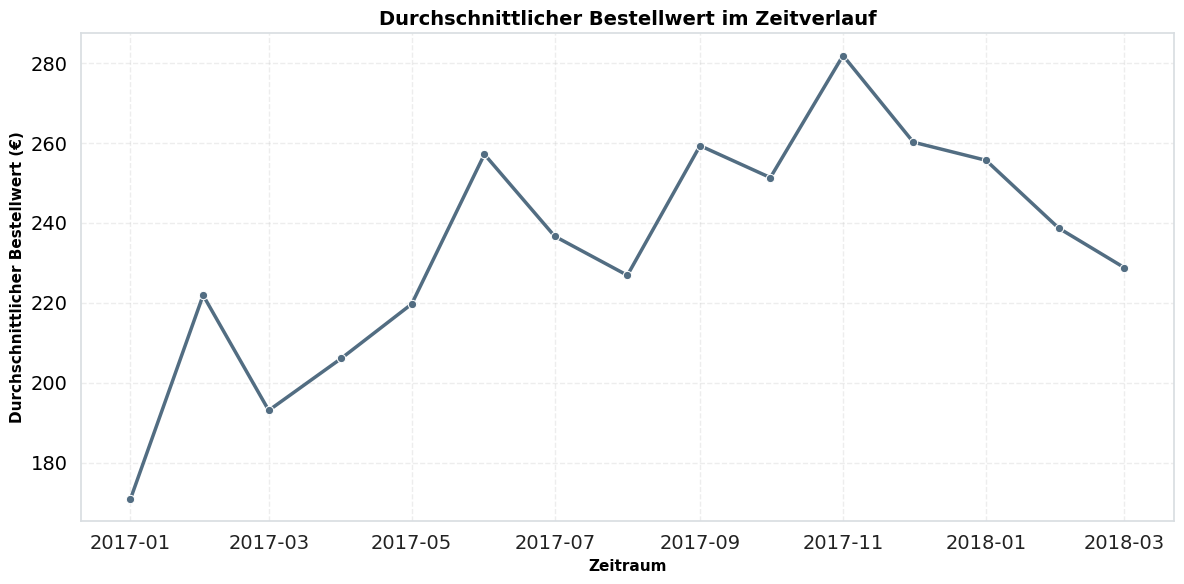

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Datum ins richtige Format umwandeln
orders_ordersline_products["created_date"] = pd.to_datetime(
    orders_ordersline_products["created_date"],
    errors="coerce"
)

# 2. Durchschnittlichen Bestellwert pro Monat berechnen
avg_order_time = (
    orders_ordersline_products
    .dropna(subset=["created_date", "total_paid"])
    .groupby(
        pd.Grouper(key="created_date", freq="MS")
    )["total_paid"]
    .mean()
    .reset_index()
)

# 3. Ergebnis anzeigen
display(avg_order_time.head())

# 4. Liniendiagramm erstellen
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=avg_order_time,
    x="created_date",
    y="total_paid",
    marker="o",
    linewidth=2.5,
    color="#526D82"
)

# 5. Titel und Beschriftungen
plt.title(
    "Durchschnittlicher Bestellwert im Zeitverlauf",
    fontsize=14,
    weight="bold"
)

plt.xlabel("Zeitraum", fontsize=11)
plt.ylabel("Durchschnittlicher Bestellwert (€)", fontsize=11)

# 6. Gitternetz
plt.grid(True, linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()